# Bouquet: reconstruction example (g-file + profile fit)

**Bouquet** turns one equilibrium into an ensemble. It perturbs the measured
inputs within their uncertainties and re-solves each draw with **TokaMaker**
(OpenFUSION Toolkit), so the spread of the draws is the uncertainty the data
allows.

This notebook starts from an EFIT-style **g-file** and an IDA-layout
**profile fit**, builds a self-consistent baseline, and draws a bouquet. It
runs on the synthetic fixtures the test suite ships (`tests/data`), so no
external data is needed:

| case | g-file | profile fit | what it is |
|---|---|---|---|
| H-mode (main) | `g_synthetic.geqdsk` | `diiid_profs_synthetic.cdf` | pedestal-forming H-mode, lower single null, 1.0 MA, B0 -2 T |
| L-mode (second case) | `g_synthetic_lmode.geqdsk` | `ida_synthetic_lmode.cdf` | sawtoothing L-mode (q0 0.8), upper single null, 1.3 MA |

The profile fit supplies n_e, T_e, T_i and Z_eff with their 1σ envelopes;
those envelopes are what the draws sample. The H-mode g-file is the thermal
equilibrium of its fit (an IDA-layout fit carries no fast-ion channel).

**Layout:** (1) the inputs, (2) a minimal run, (3) the outputs, (4) the
in-spec filter, (5) a second case on the same solver, (6) working with the
archive, (7) error bars.

**p-file route.** `from_geqdsk(g, profiles=...)` also takes an Osborne
p-file, and uses its beam-pressure block (`pb`) as the fast-ion pressure by
default. `tests/data` carries such a pair for the same slice
(`g_synthetic_pfast.geqdsk` + `p_synthetic.peqdsk`). This notebook does not
run it.

> **Prereq:** the OpenFUSION Toolkit importable (`OFT_PYTHONPATH=/path/to/OpenFUSIONToolkit/build_release/python`).
> **Runtime:** each case draws until 24 draws are in spec, roughly 40-50 solves of 1-2 min each on one core.


In [1]:
import os
import bouquet as bq
bq.add_oft_to_path()          # OFT_PYTHONPATH, known install locations or a sibling checkout
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 72})

DATA = os.path.abspath(os.path.join("..", "..", "tests", "data"))   # the synthetic fixtures
MESH = bq.find_mesh()          # the TokaMaker mesh (BOUQUET_MESH, else the one shipped in examples/)
# until-N: keep drawing until this many draws are IN SPEC (the coil test + the boundary cut).
# 24 is the default for every example; use 30 for 5/95 bands, 50 for paper-quality widths.
N_INSPEC = int(os.environ.get("BOUQUET_EXAMPLE_N_INSPEC", 24))   # (the variable is a smoke-test override)

GFILE   = os.path.join(DATA, "g_synthetic.geqdsk")          # H-mode equilibrium (shape + current)
IDA     = os.path.join(DATA, "diiid_profs_synthetic.cdf")   # its kinetic-profile fit (n, T, Z_eff + sigmas)
GFILE_L = os.path.join(DATA, "g_synthetic_lmode.geqdsk")    # the L-mode pair
IDA_L   = os.path.join(DATA, "ida_synthetic_lmode.cdf")
print("bouquet", bq.__version__, "| until-N target:", N_INSPEC)

bouquet 1.3.1 | until-N target: 24


## 1. The inputs

The **g-file** gives the equilibrium (LCFS shape, pressure, q, current, P',
FF'); the **profile fit** gives n_e, T_e, T_i and Z_eff with their 1σ
envelopes, which are the uncertainties the draws sample.


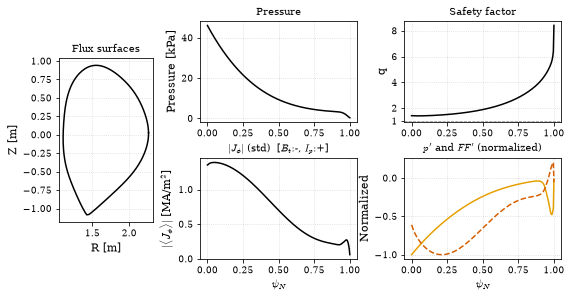

[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst -0.0% at psi_N=0.63  (report-only; see Callahan 2019 JINST 14 C10002)


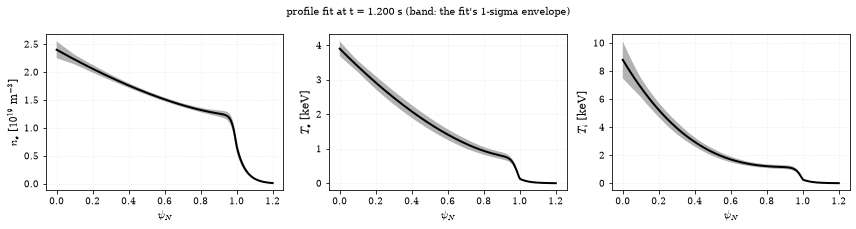

In [2]:
bq.plot_geqdsk_bouquet(GFILE); plt.show()

ida = bq.read_ida(IDA)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, (y, s, lab, sc) in zip(ax, [(ida.ne, ida.sigma_ne, r"$n_e$ [$10^{19}$ m$^{-3}$]", 1e19),
                                   (ida.te, ida.sigma_te, r"$T_e$ [keV]", 1e3),
                                   (ida.ti, ida.sigma_ti, r"$T_i$ [keV]", 1e3)]):
    a.plot(ida.psi_N, y / sc, "k"); a.fill_between(ida.psi_N, (y - s) / sc, (y + s) / sc, alpha=0.3)
    a.set_xlabel(r"$\psi_N$"); a.set_ylabel(lab); a.grid(alpha=0.3)
fig.suptitle(f"profile fit at t = {ida.time:.3f} s (band: the fit's 1-sigma envelope)", fontsize=10)
plt.tight_layout(); plt.show()

## 2. A minimal run

Create the driver, set the **until-N target** and a seed, then reconstruct and
generate. The defaults are the validated ones (the unified reconstruction
engine, the self-consistent bootstrap current, the fit file's σ, and the
in-spec rule of the magnetics: the coil χ² test and the boundary cut).

`n_inspec_target` keeps the run drawing until that many draws are in spec, so
ensembles are comparable in size whatever the yield; `n_draws` is only the
initial allocation.


In [3]:
HEADER = "synthetic_Hmode"        # output -> synthetic_Hmode.h5
run = bq.Bouquet.from_geqdsk(GFILE, profiles=IDA, mesh=MESH, n_draws=N_INSPEC,
                             header=HEADER, impurity_Z=6.0)   # carbon; set it for your machine
run.generation.n_inspec_target = N_INSPEC     # until-N: draw until N are in spec
run.generation.seed = 20261015                # reproducible perturbations
print("engine:", run.generation.reconstruction_engine, "| check_bistability:",
      run.generation.check_bistability, "(None = on under the unified engine)")

engine: unified | check_bistability: None (None = on under the unified engine)


`reconstruct()` builds the baseline from the g-file and the profile fit and
prints a **fidelity report** (TokaMaker against the input). It also runs the
**bistability check**: one extra solve of the same inputs from a cold start,
compared with the delivered state. A miss stamps the baseline and warns;
nothing is refused.


In [4]:
run.reconstruct();

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        
Development branch:  fix/jphi-update-ravgs-and-nonfinite-abort
Revision id:         7da4f18

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    1

Linear Algebra backend: native

#----------------------------------------------


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =    8910
    # of edges   =   26567
    # of cells   =   17658
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  8.702E-04
    hrms =  4.833E-02
    hmax =  1.540E-01
  Surface grounded at vertex    1733


**** Creating Lagrange FE space
  Order  =    3
  Minlev = 

 Inverting real matrix
   Time =    9.0744640000000008E-003


[engine] bistability check: single (dl_i -1.95e-06, dq0 -5.47e-06; one extra solve)


[engine] boundary partition 1.16 at W = 2e+05 (boundary 0.0919 / coils 0.079 of their cuts; 1 probe solve, 5.2 s; report only)




=== Reconstruction — g_synthetic.geqdsk ====================== PASS ✅
  converged    yes
  Ip           1.000 MA      (input 1.000 MA, -0.00%)
  l_i(3)       0.837         (input 0.837, +0.00%)
    l_i(1)x    1.072         (input 1.056, +1.53%)
  q0@0.02      1.41          (input 1.40, +0.03%)
                             (g-file axis q(0) 1.42, -0.83% -- a different radius)
  q95          4.82          (input 4.77, +1.17%)
  beta_N       0.80          (input 0.80, +0.02%)
  beta_p       0.44          (input 0.44, +1.95%)
  kappa        1.778         (input 1.754, +1.41%)
  delta        0.327         (input 0.328, -0.25%)
  j_sep(.99)   0.263 MA/m²   (input 0.237 MA/m², +10.95%)
  W_MHD        0.284 MJ      (input 0.282 MJ, +0.42%)
  p_sep        366 Pa (input edge 346.2 Pa; separatrix_pressure='offset', added back 366 Pa; edge_pprime_pin=True)
    p - p_sep  beta_N 0.771 (input 0.772, -0.16%)   W_MHD 0.2741 MJ (input 0.2735, +0.23%)
    full p     beta_N 0.797 (input 0.797, +0.02%) 

In [5]:
b = run.baseline.engine.get("bistability") or {}
print(f"bistability check: checked={b.get('checked')}  bistable={b.get('bistable')}  "
      f"outcome={b.get('outcome')}  extra solves={b.get('extra_solves')}")
for name, g in (b.get("gates") or {}).items():
    print(f"  {name:5s} = {g['value']:+.2e}  (bound {g['bound']:g}, {g['setting']})  passed={g['passed']}")

bistability check: checked=True  bistable=False  outcome=single  extra solves=1
  dl_i  = -1.95e-06  (bound 0.001, jbs_tol_li)  passed=True
  dq0   = -5.47e-06  (bound 0.002, jbs_tol_q0)  passed=True


Before spending compute on the draws, two checks: the **σ=0 identity**
(the draw route with every perturbation zero must reproduce the
reconstruction) and the input-vs-reconstruction overlay.


[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst -0.0% at psi_N=0.63  (report-only; see Callahan 2019 JINST 14 C10002)
  [sigma-source] sigma_ne   <- IDA diiid_profs_synthetic.cdf (peak 1.512e+18)
  [sigma-source] sigma_te   <- IDA diiid_profs_synthetic.cdf (peak 214.5)
  [sigma-source] sigma_ni   <- IDA diiid_profs_synthetic.cdf (peak 1.391e+18)
  [sigma-source] sigma_ti   <- IDA diiid_profs_synthetic.cdf (peak 1320)
  [sigma-source] sigma_jphi <- scalar 0.1 x |j_phi|         (peak 1.395e+05)
[sigma] zeff envelope <- carbon-propagated (n_12C6_err)
  [sigma-source] ni per draw   <- derived from the drawn (ne, Z_eff)
[boundary cut] LCFS rms <= 8.5 mm (device:DIII-D calibration: across-slice 90th percentile (8.34 mm) of the LCFS rms displacement under the magnetics' stated noise in a pre-registered boundary-UQ study, rounded to 8.5 mm; replaces the generic 5 mm; filtering.rms_max_mm overrides)


[draw-solves] 7 solves, none failed (maxits solver default)
[generate] 1 attempt(s): 1 archived, 0 rejected (not archived, not counted) -- by reason: none; axis shift: 0 of 1 archived engine draw(s) displaced > 0.01 x a from the reconstruction's axis (a displacement, not a branch label; reported, never a filter)
[sigma0-check engine route] PASS: loop: request bit-identical, converged, r_j=5.57e-05 r_I=7.81e-06 dl_i=-9.32e-07; archived: r_j=5.57e-05 r_I=7.81e-06 dl_i=-1.47e-05 dq0=+4.06e-05 dq95=+3.65e-04 dflux_rel=-2.40e-05; coils/LCFS: coil_F_drift_pct=0.00229 (bound 1), coil_VSC_drift_pct=0.0181 (bound 1), boundary_rms_mm=0.426 (bound 8.5) (tol r_j 0.001, r_I 0.0001, l_i 0.001, q0 0.002)


sigma=0 identity passed: True


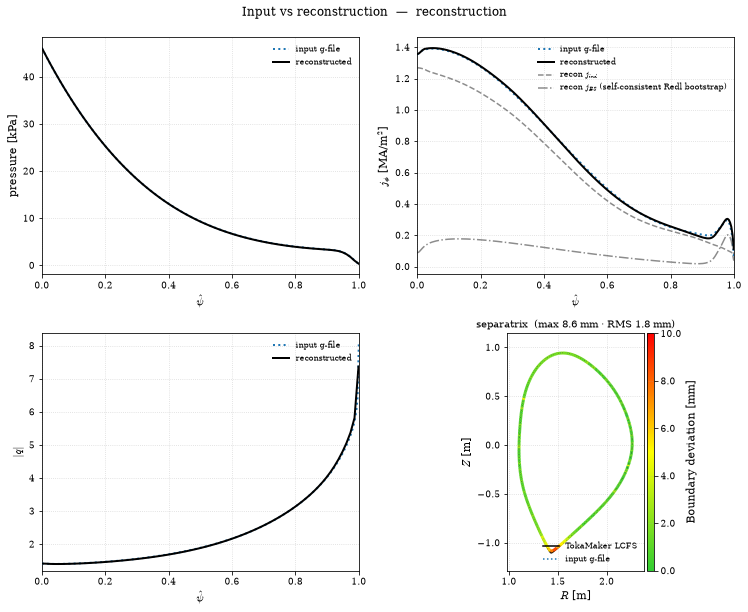

In [6]:
chk = run.verify_sigma0_consistency()
print("sigma=0 identity passed:", chk["passed"])
bq.plot_input_vs_recon(run); plt.show()

In [7]:
run.generate(); run.filter(); run.export();    # draw until N in spec, screen, write the in-spec file

[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst -0.0% at psi_N=0.63  (report-only; see Callahan 2019 JINST 14 C10002)
  [sigma-source] sigma_ne   <- IDA diiid_profs_synthetic.cdf (peak 1.512e+18)
  [sigma-source] sigma_te   <- IDA diiid_profs_synthetic.cdf (peak 214.5)
  [sigma-source] sigma_ni   <- IDA diiid_profs_synthetic.cdf (peak 1.391e+18)
  [sigma-source] sigma_ti   <- IDA diiid_profs_synthetic.cdf (peak 1320)
  [sigma-source] sigma_jphi <- scalar 0.1 x |j_phi|         (peak 1.395e+05)
[sigma] zeff envelope <- carbon-propagated (n_12C6_err)
  [sigma-source] ni per draw   <- derived from the drawn (ne, Z_eff)


[draw-solves] 1/295 solves failed (1 exceeded maxits solver default), 25 s; recovered 0; lost 1, draws [17]: solve:1538 x1
[generate] 25 attempt(s): 24 archived, 1 rejected (not archived, not counted) -- by reason: homotopy_saturated=1; axis shift: 2 of 24 archived engine draw(s) displaced > 0.01 x a from the reconstruction's axis (a displacement, not a branch label; reported, never a filter); axis not bimodal (24 draws; largest gap 0.7 mm vs within-cluster spread 1.4 mm)
[generate] 1 engine-draw GS solve(s) stopped at engine_draw_solve_maxits=100: homotopy rolled_back x1; per-solve records: Bouquet.engine_draw_cap_events
[generate] 1 of them labelled vertical_runaway (the vertical-control channel at its homotopy bound, the axis displaced vertically > 0.1 a; a label, not a gate)


[until-N] target met: 24/24 in-spec draws in 25 attempts.


[axis] scan 0: axis not bimodal (24 draws; largest gap 0.7 mm vs within-cluster spread 1.4 mm)


  coil chi2 filter: era undetermined (BouquetConfig.device is not set, so no era table applies yet) -> the device detected from the mesh uses its default band, which carries the TIGHTEST floor  [set filtering.coil_daq_era to state the era]


filtering.py:1316: UserWarning: coil tolerance: no era given for device 'DIII-D', whose sigma floor is era-dependent (known eras: ['modern', 'pre2014']). Falling back to the default band, which carries the TIGHTEST floor -- an unknown era must not buy a looser tolerance. Set filtering.coil_daq_era explicitly (or supply an explicit pulse number on the source) to select the right one.
  sig, model = resolve_coil_sigma(baseline, sigma=sigma, device=device, era=era)
run.py:8679: UserWarning: coil filter: acceptance chi2/nu <= 6.1 and max|z| <= 6.3 were calibrated over 18 coils but are being applied over 20. These are empirical quantiles, not dof-based bounds: max|z| is an order statistic whose quantile rises with the coil count, so the true false-rejection rate is ABOVE the nominal 5%. Thresholds are unchanged; recalibrate them over the judged coil set, or restrict the metric to the calibrated set, before relying on the quantile.
  coil_summary = filter_coil_chi2(



=== Bouquet — synthetic_Hmode ===================  24/24 in-spec (100%)
  draws         24 generated to deliver 24/24 requested in-spec (target met)
  coil spec     24/24 chi2/nu <= 6.1, |z| <= 6.3 [device q95, 20 coils]   (0 out-of-spec)
  boundary      RMS median 3.00 mm   max 7.58 mm
  in-spec rule  magnetics   (coil test + boundary cut; l_i, beta_p and Lambda reported, not filtered)


## 3. The outputs

- **`plot_traces`**: per-draw l_i, the LCFS deviation against the boundary cut,
  and the anchor-displacement heatmap;
- **`plot_bouquet(mode="j-phi")`**: the current-profile family (other modes:
  `kinetic`, `pressure`, `boundary`, `all`).

Filled markers are in-spec draws; open markers were excluded by the filter.


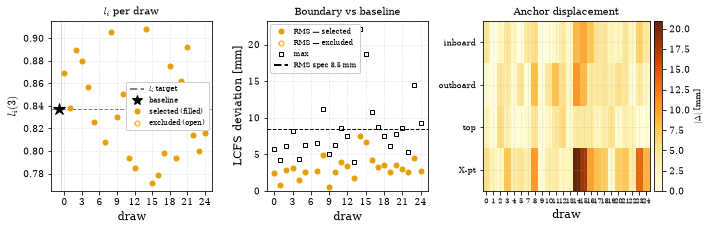

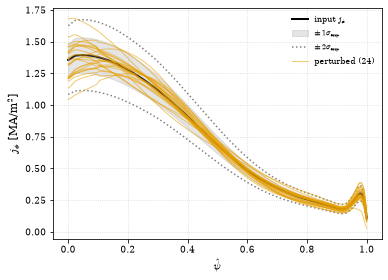

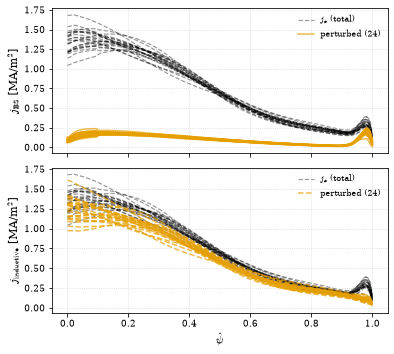

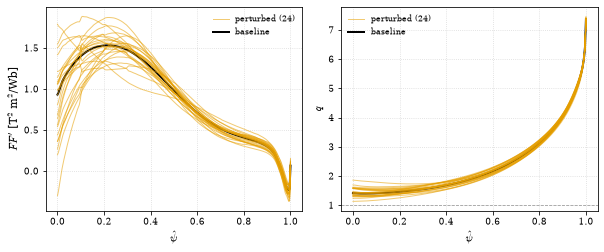

In [8]:
bq.plot_traces(HEADER + ".h5", scan_key=0, rms_max_mm=run.boundary_cut()[0]); plt.show()
bq.plot_bouquet(HEADER + ".h5", scan_key=0, mode="j-phi", selection="selected"); plt.show()

## 4. The in-spec filter

`run.filter()` screened the draws with the **coil test** (a χ² of the coil
currents against the device's coil uncertainties) and the **boundary cut**
(the RMS deviation of the last closed surface against the device's calibrated
threshold). `selected` is their AND. The flags are read back here; a re-cut
at a different threshold is a what-if with `apply=False`.


stored draws: 24   coil test pass: 24   boundary cut pass: 24   in spec: 24


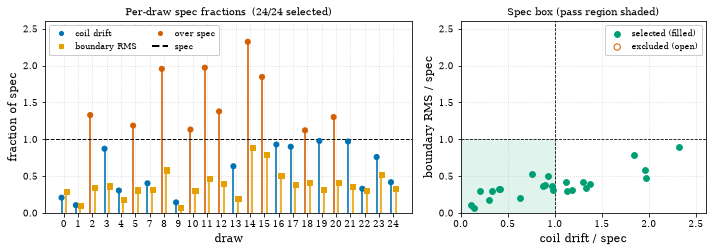

what-if at half the boundary cut (4.25 mm): 5/24 draws would fail


In [9]:
flags = bq.read_filter_flags(HEADER, scan_key=0)
n_coil = sum(f.get("passes_coil_filter", False) for f in flags.values())
n_bnd = sum(f.get("passes_boundary_filter", False) for f in flags.values())
sel = bq.select_indices(HEADER, scan_key=0, selection="selected")
print(f"stored draws: {len(flags)}   coil test pass: {n_coil}   boundary cut pass: {n_bnd}   in spec: {len(sel)}")
rms_cut = run.boundary_cut()[0]
bq.plot_spec_summary(HEADER, scan_key=0, rms_max_mm=rms_cut); plt.show()
bs, _ = bq.filter_boundaries(HEADER, rms_max_mm=0.5 * rms_cut, scan_key=0, apply=False, plot=False)
print(f"what-if at half the boundary cut ({0.5 * rms_cut:.2f} mm): "
      f"{sum(not d['passes'] for d in bs['draws'].values())}/{bs['n_total']} draws would fail")

## 5. A second case on the same solver: the L-mode pair

`set_case` points the driver at a new baseline and keeps the solver (the
OpenFUSION environment is one per process). The run settings carry over; the
σ come from the new fit file.


In [10]:
HEADER_L = "synthetic_Lmode"
src_l = bq.Bouquet.from_geqdsk(GFILE_L, profiles=IDA_L, mesh=MESH, impurity_Z=6.0).config.source
run.set_case(source=src_l, header=HEADER_L, scan_key=0)
run.reconstruct();
print("sigma=0 identity passed:", run.verify_sigma0_consistency()["passed"])
run.generate(); run.filter(); run.export();

[engine] bistability check: single (dl_i -1.49e-06, dq0 -8.14e-06; one extra solve)


[engine] boundary partition 1.38 at W = 2e+05 (boundary 0.0851 / coils 0.0618 of their cuts; 1 probe solve, 5.4 s; report only)




=== Reconstruction — g_synthetic_lmode.geqdsk ================ PASS ✅
  converged    yes
  Ip           1.300 MA      (input 1.300 MA, -0.00%)
  l_i(3)       1.042         (input 1.042, -0.06%)
    l_i(1)x    1.300         (input 1.289, +0.86%)
  q0@0.02      0.81          (input 0.81, -0.42%)
                             (g-file axis q(0) 0.80, +0.73% -- a different radius)
  q95          3.81          (input 3.79, +0.42%)
  beta_N       0.79          (input 0.80, -1.04%)
  beta_p       0.35          (input 0.35, -0.16%)
  kappa        1.715         (input 1.708, +0.40%)
  delta        0.423         (input 0.406, +4.16%)
  j_sep(.99)   0.064 MA/m²   (input 0.004 MA/m², +1427.98%)
  W_MHD        0.382 MJ      (input 0.387 MJ, -1.07%)
  p_sep        591.5 Pa (input edge 592.9 Pa; separatrix_pressure='offset', added back 591.5 Pa; edge_pprime_pin=True)
    p - p_sep  beta_N 0.758 (input 0.766, -1.08%)   W_MHD 0.3662 MJ (input 0.3704, -1.11%)
    full p     beta_N 0.792 (input 0.800, -1

[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst +0.0% at psi_N=0.69  (report-only; see Callahan 2019 JINST 14 C10002)
  [sigma-source] sigma_ne   <- IDA ida_synthetic_lmode.cdf  (peak 1.98e+18)
  [sigma-source] sigma_te   <- IDA ida_synthetic_lmode.cdf  (peak 145.8)
  [sigma-source] sigma_ni   <- IDA ida_synthetic_lmode.cdf  (peak 1.742e+18)
  [sigma-source] sigma_ti   <- IDA ida_synthetic_lmode.cdf  (peak 296)
  [sigma-source] sigma_jphi <- scalar 0.1 x |j_phi|         (peak 2.504e+05)
[sigma] zeff envelope <- carbon-propagated (n_12C6_err)
  [sigma-source] ni per draw   <- derived from the drawn (ne, Z_eff)
[boundary cut] LCFS rms <= 8.5 mm (device:DIII-D calibration: across-slice 90th percentile (8.34 mm) of the LCFS rms displacement under the magnetics' stated noise in a pre-registered boundary-UQ study, rounded to 8.5 mm; replaces the generic 5 mm; filtering.rms_max_mm overrides)


[draw-solves] 7 solves, none failed (maxits solver default)
[generate] 1 attempt(s): 1 archived, 0 rejected (not archived, not counted) -- by reason: none; axis shift: 0 of 1 archived engine draw(s) displaced > 0.01 x a from the reconstruction's axis (a displacement, not a branch label; reported, never a filter)
[sigma0-check engine route] PASS: loop: request bit-identical, converged, r_j=6.05e-05 r_I=5.46e-06 dl_i=-2.39e-05; archived: r_j=6.05e-05 r_I=5.46e-06 dl_i=-4.78e-05 dq0=+2.81e-05 dq95=+2.95e-04 dflux_rel=-3.25e-05; coils/LCFS: coil_F_drift_pct=0.000813 (bound 1), coil_VSC_drift_pct=0.0413 (bound 1), boundary_rms_mm=0.472 (bound 8.5) (tol r_j 0.001, r_I 0.0001, l_i 0.001, q0 0.002)


...

[until-N] target met: 24/24 in-spec draws in 24 attempts.


[axis] scan 0: axis not bimodal (24 draws; largest gap 0.9 mm vs within-cluster spread 1.4 mm)


  coil chi2 filter: era undetermined (BouquetConfig.device is not set, so no era table applies yet) -> the device detected from the mesh uses its default band, which carries the TIGHTEST floor  [set filtering.coil_daq_era to state the era]


filtering.py:1316: UserWarning: coil tolerance: no era given for device 'DIII-D', whose sigma floor is era-dependent (known eras: ['modern', 'pre2014']). Falling back to the default band, which carries the TIGHTEST floor -- an unknown era must not buy a looser tolerance. Set filtering.coil_daq_era explicitly (or supply an explicit pulse number on the source) to select the right one.
  sig, model = resolve_coil_sigma(baseline, sigma=sigma, device=device, era=era)
run.py:8679: UserWarning: coil filter: acceptance chi2/nu <= 6.1 and max|z| <= 6.3 were calibrated over 18 coils but are being applied over 20. These are empirical quantiles, not dof-based bounds: max|z| is an order statistic whose quantile rises with the coil count, so the true false-rejection rate is ABOVE the nominal 5%. Thresholds are unchanged; recalibrate them over the judged coil set, or restrict the metric to the calibrated set, before relying on the quantile.
  coil_summary = filter_coil_chi2(



=== Bouquet — synthetic_Lmode ===================  24/24 in-spec (100%)
  draws         24 generated to deliver 24/24 requested in-spec (target met)
  coil spec     24/24 chi2/nu <= 6.1, |z| <= 6.3 [device q95, 20 coils]   (0 out-of-spec)
  boundary      RMS median 2.40 mm   max 7.52 mm
  in-spec rule  magnetics   (coil test + boundary cut; l_i, beta_p and Lambda reported, not filtered)


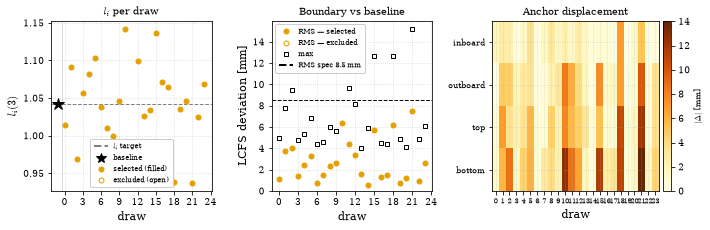

In [11]:
bq.plot_traces(HEADER_L + ".h5", scan_key=0, rms_max_mm=run.boundary_cut()[0]); plt.show()

## 6. Working with the archive

Every run writes a self-contained HDF5 archive: per-draw profiles, separated
currents, scalars, coil currents and the raw g-file bytes of each perturbed
equilibrium. `BouquetArchive` walks it; any draw's g-file can be written out
for an external code.


In [12]:
import tempfile
ar = bq.BouquetArchive(HEADER + ".h5")
sc = ar[ar.scan_keys[0]]
d = sc.selected[0]
eq = d.equilibrium()
print(f"draw {d.count}: l_i(3) = {d.li3:.3f}, Ip = {abs(eq.Ip) / 1e6:.3f} MA, "
      f"q95 = {np.interp(0.95, eq.psi_N, np.abs(eq.qpsi)):.2f}")
print("profiles stored per draw:", sorted(d.profiles)[:8], "...")
out = d.extract(tempfile.mkdtemp(), formats=("geqdsk",))
print("extracted:", {k: os.path.basename(v) for k, v in out.items()})

draw 0: l_i(3) = 0.869, Ip = 1.000 MA, q95 = 4.77
profiles stored per draw: ['T_e', 'T_i', 'aux_zeff', 'coil_currents', 'j_BS', 'j_NBI', 'j_RF', 'j_inductive'] ...
extracted: {'geqdsk': 'synthetic_Hmode_0_0.geqdsk'}


## Error bars

`bq.bands_summary` turns an archive into error bars in one call. For each
quantity it reports the **median, the 16–84 % band, the full range and n**
over the in-spec draws. The reconstruction is drawn for reference but is never
the centre of a band: the band is the draws. The two gradients, `dp_dpsi` and
`djphi_dpsi`, are taken on each draw's own q = 2 surface; draws without one
are excluded and counted, and if none has one the helper falls back to
ψ_N = 0.5 and says so. Every record keeps its provenance, the counts at each
stage, the dropped draws and why, and any caveats, in `summary[q].provenance`.

24 in-spec draws is the default; use 30 for 5–95 % bands and 50 for
publication figures.


synthetic_Hmode
Error bars over the in-spec draws of scan '0': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N           0.7979       0.7715       0.8313       0.7466       0.8665    24  
l_i_3            0.8334       0.7935       0.8831       0.7715       0.9086    24  
Lambda           0.8631       0.8455       0.8886       0.8219       0.8954    24  
dp_dpsi      -2.711e+04   -3.048e+04   -2.251e+04   -3.531e+04   -2.012e+04    24  Pa/psi_N
djphi_dpsi   -2.033e+06   -2.307e+06   -1.871e+06   -2.681e+06   -1.432e+06    24  A m^-2/psi_N



synthetic_Lmode
Error bars over the in-spec draws of scan '0': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N           0.7996       0.7756       0.8116       0.7139       0.8378    24  
l_i_3             1.042       0.9934        1.094       0.9368        1.142    24  
Lambda            0.875       0.8482       0.8882       0.8242       0.9164    24  
dp_dpsi      -2.651e+04    -2.89e+04   -2.374e+04   -2.956e+04   -2.276e+04    24  Pa/psi_N
djphi_dpsi   -1.711e+06   -1.894e+06   -1.595e+06   -2.023e+06   -1.317e+06    24  A m^-2/psi_N



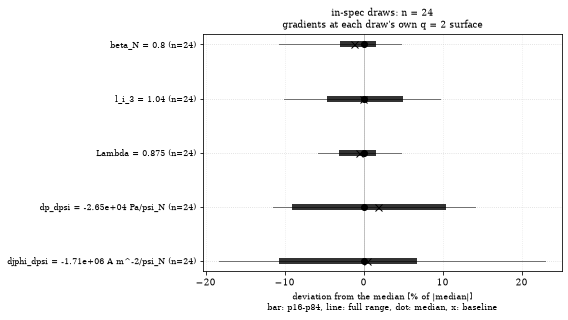

In [13]:
for h in (HEADER, HEADER_L):
    summary = bq.bands_summary(h + ".h5", 0, scalars=("beta_N", "l_i_3", "Lambda"),
                               gradients=("dp_dpsi", "djphi_dpsi"), at={"q": 2.0},
                               fallback_psi_N=0.5)
    print(h); print(summary.table()); print()
summary.plot(); plt.show()      # one band figure (the L-mode case), n stated